# Bitcoin price prediction with statistical signal processing
**EE4795 Statistical Digital Signal Processing, TU Delft 2026/27 Q1, Project 9**
Naufal el Khatibi, Omar Shousha

This notebook produces every number, table and figure in the report (`../report/report.pdf`). It is run top to bottom with *Kernel > Restart & Run All* (about 1 minute). The algorithms are in the `sdsp` package:
- `sdsp/data.py`: loading, cleaning and the chronological split
- `sdsp/models.py`: Levinson–Durbin, AR, Wiener, LMS/NLMS, RLS and Kalman filters, written from scratch in NumPy
- `sdsp/evaluation.py`: tuning, walk-forward test, metrics, Diebold–Mariano and whiteness tests

**Notation** (as in the report)

| Symbol | Meaning |
|---|---|
| $p[n]$ | daily closing price (USD) |
| $x[n]=\ln p[n]$ | log-price |
| $r[n]=x[n]-x[n-1]$ | log-return |
| $\hat r[n]$ | one-step prediction of $r[n]$ from $r[1],\dots,r[n-1]$ |
| $\hat p[n]=p[n-1]e^{\hat r[n]}$ | price prediction |
| $\mathbf a=[a_1..a_p]^T$ | AR / predictor coefficients |
| $\sigma^2$ | variance of $r[n]$ |

$N=365$ counts prices and $364$ counts returns.

**Protocol rule.** No choice of any kind (model order, step size, forgetting factor, noise variance) is made on the test block. The data-model statistics in Sections 2.2–2.3 use only pre-test data (fit + validation).

**Contents** (numbered as the report sections)
- 2.1 Data and cross-check
- 2.2 Statistics and data model
- 2.3 Spectral analysis
- 3.1 Wiener–AR equivalence
- 3.2 Tuning on the validation block
- 4.1 Test results
- 4.2 Why validation and test disagree
- 4.3 Multi-step forecasts
- 4.4 Open, High and Low
- 4.5 Recent data
- 4.6 Full-history robustness
- Summary

## Setup

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats, signal

ROOT = Path.cwd().resolve()
if not (ROOT / "sdsp").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*InterpolationWarning.*")
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.filterwarnings("ignore", category=InterpolationWarning)

from sdsp.data import (load_raw, clean, add_returns, load_dataset, load_full, Series,
                       FULL_CSV, RECENT_CSV)
from sdsp.models import (autocorr, ar_fit, ar_order_criteria, ar_spectrum, wiener_predictor, rls_predict)
from sdsp.evaluation import (run_all, tune, horizon_errors, dm_test, evaluate_test, pred_rls,
                             year_table, RLS_LAMBDAS, ORDERS)
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.multitest import multipletests

FIG = ROOT / "results" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / "results" / "tables";  TAB.mkdir(parents=True, exist_ok=True)
# Categorical palette, fixed order (checked for colour-vision deficiency); black = truth / naive
COL = {"Naive (random walk)": "#0b0b0b", "Drift": "#8a8987", "AR": "#2a78d6", "LMS": "#eb6834",
       "NLMS": "#e87ba4", "RLS": "#1baf7a", "Kalman TV-AR": "#eda100", "Kalman local level": "#6250d6"}
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.2,
                     "legend.frameon": False, "savefig.bbox": "tight"})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

## 2.1 Data and cross-check
The course file contains Yahoo Finance daily BTC-USD data, 6 Aug 2020 – 6 Aug 2021. Every close in it is compared with the Yahoo Finance history downloaded on 16 Oct 2026 (`data/full`).
- **Empty days:** 9, 12 and 13 Oct 2020 are completely empty (`null`). They are filled by linear interpolation of the **log**-price, i.e. a constant return across the gap, and no prediction is scored on them.
- **Last row:** 6 Aug 2021 was saved before the day had closed, so it is dropped.
- **Revised days:** some other days were revised by Yahoo after the course file was made; see the comparison below.

In [2]:
raw = load_raw()
print(f"raw file: {len(raw)} rows, {raw.index.min().date()} to {raw.index.max().date()}; "
      f"missing days: {[d.date().isoformat() for d in raw.index[raw['Close'].isna()]]}")
full_close = pd.read_csv(FULL_CSV, parse_dates=["Date"]).set_index("Date")["Close"]
cmp = pd.DataFrame({"course_Close": raw["Close"], "yahoo_Close_2026-10-16": full_close.reindex(raw.index)})
cmp["diff_USD"] = cmp.iloc[:, 1] - cmp.iloc[:, 0]
cmp["diff_%"] = 100 * cmp["diff_USD"] / cmp["course_Close"]
both = cmp.dropna()
print(f"days compared: {len(both)}; agree within 1 cent: {(both.diff_USD.abs() <= 0.01).sum()}; "
      f"differ: {(both.diff_USD.abs() > 0.01).sum()}")
print(both[both.diff_USD.abs() > 0.01].round(2))
cmp.round(4).to_csv(ROOT / "data" / "course" / "yahoo_crosscheck.csv")

raw file: 366 rows, 2020-08-06 to 2021-08-06; missing days: ['2020-10-09', '2020-10-12', '2020-10-13']
days compared: 363; agree within 1 cent: 345; differ: 18
            course_Close  yahoo_Close_2026-10-16  diff_USD  diff_%
Date                                                              
2020-09-23      10225.86                10246.19     20.33    0.20
2020-09-24      10745.55                10760.07     14.52    0.14
2020-09-25      10702.29                10692.72     -9.57   -0.09
2020-09-26      10754.44                10750.72     -3.72   -0.03
2020-09-27      10774.43                10775.27      0.84    0.01
2020-09-28      10721.33                10709.65    -11.68   -0.11
2020-09-29      10848.83                10844.64     -4.19   -0.04
2020-09-30      10787.62                10784.49     -3.13   -0.03
2020-10-01      10623.33                10619.45     -3.88   -0.04
2020-10-02      10585.16                10575.97     -9.19   -0.09
2020-10-03      10565.49            

In [3]:
df = load_dataset()                       # cleaned, ends 2021-08-05, adds logp and r
assert df.index.to_series().diff().dropna().eq(pd.Timedelta("1D")).all()
S = Series(df)                            # fixes the split used everywhere
N = len(df)
print(f"used: {N} prices ({df.index.min().date()} to {df.index.max().date()}), {N-1} returns")
for name, pos in [("fit", np.arange(1, S.val[0])), ("validation", S.val), ("test", S.test)]:
    print(f"{name:>10}: {df.index[pos[0]].date()} to {df.index[pos[-1]].date()}  ({len(pos)} returns)")
pre = np.arange(1, S.test[0])             # all pre-test returns (fit + validation)

used: 365 prices (2020-08-06 to 2021-08-05), 364 returns
       fit: 2020-08-07 to 2021-03-27  (233 returns)
validation: 2021-03-28 to 2021-05-24  (58 returns)
      test: 2021-05-25 to 2021-08-05  (73 returns)


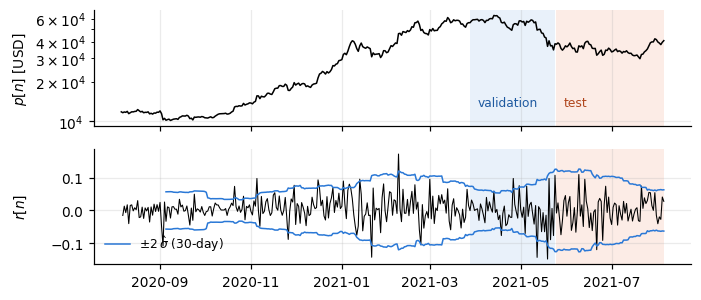

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(7, 3.0), sharex=True)
ax[0].semilogy(df.index, df["Close"], color="k", lw=1)
ax[0].set_ylabel("$p[n]$ [USD]")
for a in ax:
    a.axvspan(df.index[S.val[0]], df.index[S.val[-1]], color="#2a78d6", alpha=0.10, lw=0)
    a.axvspan(df.index[S.test[0]], df.index[S.test[-1]], color="#eb6834", alpha=0.12, lw=0)
ax[0].text(df.index[S.val[5]], 13000, "validation", fontsize=8, color="#1f5aa0")
ax[0].text(df.index[S.test[5]], 13000, "test", fontsize=8, color="#b0461d")
ax[1].plot(df.index, df["r"], color="k", lw=0.7)
roll = df["r"].rolling(30).std()
ax[1].plot(df.index, 2*roll, color="#2a78d6", lw=1, label=r"$\pm 2\,\hat\sigma$ (30-day)")
ax[1].plot(df.index, -2*roll, color="#2a78d6", lw=1)
ax[1].set_ylabel("$r[n]$"); ax[1].legend(loc="lower left", fontsize=8)
fig.align_ylabels(); fig.savefig(FIG / "fig_data.pdf"); plt.show()

## 2.2 Statistics and data model (pre-test data only)
The assumptions of the linear predictors from the course are tested:
- **Stationarity:** ADF and KPSS (with a constant; for the price also with a trend).
- **Gaussianity:** Jarque–Bera.
- **Whiteness of $r$:** sample ACF and Ljung–Box.
- **Volatility clustering:** Ljung–Box on $r^2$.
- **Constant variance:** F-test comparing the two halves.

Everything here uses the 291 pre-test returns. The full-sample values are printed for comparison only.

In [5]:
def describe(r):
    return pd.Series({"N": len(r), "mean": r.mean(), "std": r.std(ddof=1), "skewness": stats.skew(r),
                      "excess kurtosis": stats.kurtosis(r), "t-test mean=0, p": stats.ttest_1samp(r, 0).pvalue,
                      "Jarque-Bera p": stats.jarque_bera(r).pvalue})
r = S.r[pre]; Nr = len(r); xpre = S.x[: S.test[0]]
print(pd.DataFrame({"pre-test": describe(r), "full sample (reference)": describe(S.r[1:])}).to_string(float_format=lambda v: f"{v:.4g}"))
tests = []
for name, z, reg in [("log-price x[n]", xpre, "c"), ("log-price x[n], trend", xpre, "ct"), ("log-return r[n]", r, "c")]:
    a = adfuller(z, regression=reg, autolag="AIC"); k = kpss(z, regression=reg, nlags="auto")
    tests.append({"series": name, "ADF stat": a[0], "ADF p": a[1], "KPSS stat": k[0], "KPSS p": k[1]})
print(pd.DataFrame(tests).set_index("series").round(4))
lb = pd.DataFrame({"r[n]": acorr_ljungbox(r, lags=[5, 10, 20])["lb_pvalue"],
                   "r^2[n]": acorr_ljungbox(r**2, lags=[5, 10, 20])["lb_pvalue"]})
lb.index.name = "Ljung-Box p at lag"; print(lb.round(4))
h = Nr // 2; F = np.var(r[h:], ddof=1) / np.var(r[:h], ddof=1)
pF = 2 * min(stats.f.sf(F, Nr-h-1, h-1), stats.f.cdf(F, Nr-h-1, h-1))
print(f"std first half {r[:h].std():.4f}, second half {r[h:].std():.4f}, variance ratio F = {F:.2f}, p = {pF:.2g} (i.i.d. F-test)")
crit = ar_order_criteria(r, 20)
print("AIC picks p =", crit["AIC"].argmin(), "| MDL picks p =", crit["MDL"].argmin(),
      "| reflection coefficients 1..8:", crit["pacf"][1:9].round(3))

                  pre-test  full sample (reference)
N                      291                      364
mean              0.004088                 0.003418
std                0.04002                  0.04022
skewness           -0.1565                  -0.1498
excess kurtosis      2.554                     2.11
t-test mean=0, p   0.08245                   0.1058
Jarque-Bera p    3.659e-18                1.091e-15
                       ADF stat   ADF p  KPSS stat  KPSS p
series                                                    
log-price x[n]          -0.9974  0.7542      2.614    0.01
log-price x[n], trend   -0.3851  0.9873      0.313    0.01
log-return r[n]        -17.9619  0.0000      0.336    0.10
                      r[n]  r^2[n]
Ljung-Box p at lag                
5                   0.4247  0.4948
10                  0.6300  0.0295
20                  0.6381  0.0055
std first half 0.0284, second half 0.0487, variance ratio F = 2.94, p = 2.7e-10 (i.i.d. F-test)
AIC picks p = 0 | 

**Data model.**
- **Log-price $x[n]$:** has a unit root. ADF cannot reject it (with or without a trend), and KPSS rejects stationarity.
- **Log-returns $r[n]$:** the increments are stationary in the mean, with a mean not significantly different from zero.
- **Linear dependence:** none is detectable. Ljung–Box on $r$ does not reject whiteness, AIC and MDL pick $p=0$, and 19 of the 20 ACF lags lie inside the bound.
- **Not i.i.d. Gaussian:** the tails are heavy, $r^2$ is correlated (volatility clustering), and the variance differs significantly between the two halves.

$r[n]$ is therefore treated as **wide-sense stationary over the sample, with a conditional variance that changes over time** (GARCH-type behaviour). The ACF and spectrum are estimated from a single record, which assumes ergodicity.

The minimum-MSE predictor is the conditional mean $E\{r[n]\mid r[n-1],\dots\}$. If the returns are white, the best *linear* predictor is the mean, i.e. $\hat r\approx0$ (the random walk). Ljung–Box and the $\pm1.96/\sqrt N$ bound tend to reject too often under volatility clustering, so "no rejection" is conservative.

$$x[n]=x[n-1]+r[n],\qquad r[n]=\sum_{k=1}^{p}a_k r[n-k]+e[n]$$

## 2.3 Spectral analysis (pre-test data)
- **Periodogram:** inconsistent.
- **Bartlett:** $K=8$ non-overlapping rectangular segments. Variance $\approx P^2/K$, resolution $0.89\cdot2\pi/L$.
- **Welch:** Hann window, $L=64$, 50 % overlap. The course gives the variance for 50 % overlap as $\approx\frac{9}{8K}P^2$ (Lecture 10, Bartlett window), with resolution $1.44\cdot2\pi/L$ for Hann.
- **AR(4) spectrum** for comparison. The dashed band is the approximate 95 % interval for a flat spectrum, using $K_{\rm eff}=8K/9$ $\chi^2$ degrees of freedom.

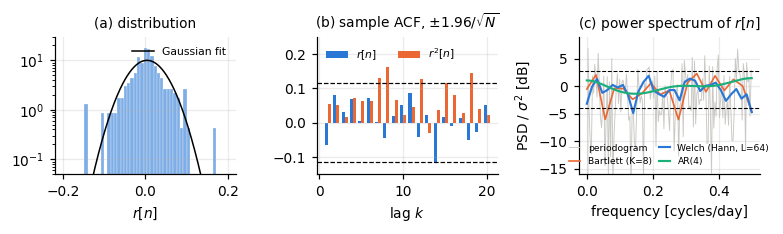

Welch: K=8, band [-3.92, 2.69] dB, bins outside: 0.06; Bartlett resolution 0.89/L = 0.025 cycles/day; Welch 1.44/64 = 0.022; AR(4) spectrum range [-1.38, 1.46] dB


In [6]:
rc = r - r.mean(); var = rc.var()
f_p, P_per = signal.periodogram(rc, fs=1.0, window="boxcar", detrend=False, scaling="density")
L_b = Nr // 8
f_b, P_bart = signal.welch(rc, fs=1.0, window="boxcar", nperseg=L_b, noverlap=0, detrend=False, scaling="density")
f_w, P_welch = signal.welch(rc, fs=1.0, window="hann", nperseg=64, noverlap=32, detrend=False, scaling="density")
a4, mu4, s4 = ar_fit(r, 4)
w_ar, P_ar = ar_spectrum(a4, s4); f_ar = w_ar / (2 * np.pi)
K_w = 1 + (Nr - 64) // 32; K_eff = 8 * K_w / 9
lo, hi = stats.chi2.ppf([0.025, 0.975], 2 * K_eff) / (2 * K_eff)
fig, axs = plt.subplots(1, 3, figsize=(7.2, 2.2))
xg = np.linspace(-0.2, 0.2, 400)
axs[0].hist(r, bins=40, density=True, color="#2a78d6", alpha=0.6, edgecolor="white", linewidth=0.3)
axs[0].plot(xg, stats.norm.pdf(xg, r.mean(), r.std()), color="k", lw=1, label="Gaussian fit")
axs[0].set_yscale("log"); axs[0].set_ylim(0.05, 30); axs[0].set_xlabel("$r[n]$"); axs[0].set_title("(a) distribution", fontsize=9)
axs[0].legend(fontsize=7)
lags = np.arange(1, 21); bound = 1.96 / np.sqrt(Nr)
axs[1].bar(lags - 0.18, acf(r, nlags=20)[1:], width=0.36, color="#2a78d6", label="$r[n]$")
axs[1].bar(lags + 0.18, acf(r**2, nlags=20)[1:], width=0.36, color="#eb6834", label="$r^2[n]$")
axs[1].axhline(bound, color="k", ls="--", lw=0.8); axs[1].axhline(-bound, color="k", ls="--", lw=0.8)
axs[1].set_ylim(-0.15, 0.25); axs[1].set_xlabel("lag $k$"); axs[1].set_title(r"(b) sample ACF, $\pm1.96/\sqrt{N}$", fontsize=9)
axs[1].legend(fontsize=7, loc="upper left", ncol=2)
db = lambda P: 10 * np.log10(P / (2 * var))
axs[2].plot(f_p, db(P_per), color="#c9c8c4", lw=0.6, label="periodogram")
axs[2].plot(f_b, db(P_bart), color="#eb6834", lw=1.1, label=f"Bartlett (K={Nr//L_b})")
axs[2].plot(f_w, db(P_welch), color="#2a78d6", lw=1.4, label="Welch (Hann, L=64)")
axs[2].plot(f_ar, 10*np.log10(P_ar / var), color="#1baf7a", lw=1.4, label="AR(4)")
axs[2].axhline(10*np.log10(lo), color="k", ls="--", lw=0.7); axs[2].axhline(10*np.log10(hi), color="k", ls="--", lw=0.7)
axs[2].set_ylim(-16, 9); axs[2].set_xlabel("frequency [cycles/day]"); axs[2].set_ylabel(r"PSD / $\sigma^2$ [dB]")
axs[2].set_title("(c) power spectrum of $r[n]$", fontsize=9)
axs[2].legend(fontsize=6, loc="lower center", ncol=2, handlelength=1.2, columnspacing=0.8)
fig.tight_layout(); fig.savefig(FIG / "fig_stats.pdf"); plt.show()
out = (P_welch/(2*var) < lo) | (P_welch/(2*var) > hi)
print(f"Welch: K={K_w}, band [{10*np.log10(lo):.2f}, {10*np.log10(hi):.2f}] dB, bins outside: {out.mean():.2f}; "
      f"Bartlett resolution 0.89/L = {0.89/L_b:.3f} cycles/day; Welch 1.44/64 = {1.44/64:.3f}; "
      f"AR(4) spectrum range [{10*np.log10(P_ar.min()/var):.2f}, {10*np.log10(P_ar.max()/var):.2f}] dB")

## 3.1 Wiener–AR equivalence and prediction gain
The one-step FIR Wiener predictor satisfies $\mathbf R_r\mathbf w=[r_r(1),\dots,r_r(L)]^T$; these are the Yule–Walker equations. They are solved in two independent ways: a Toeplitz solver and the Levinson–Durbin recursion. The prediction gain is $G=r_r(0)/\xi_{\min}$.

In [7]:
fit_end = S.val[0]
hfit = S.r[1:fit_end]
rows = []
for L in [1, 2, 4, 8]:
    w, _, xi = wiener_predictor(hfit, L, demean=False)
    a, _, s2 = ar_fit(hfit, L, demean=False)
    rows.append({"L": L, "max |w - a|": np.max(np.abs(w - a)), "xi_min": xi, "gain G [dB]": 10*np.log10(autocorr(hfit, 0)[0] / xi)})
print(pd.DataFrame(rows).set_index("L").to_string(float_format=lambda v: f"{v:.3g}"))

   max |w - a|  xi_min  gain G [dB]
L                                  
1            0 0.00142      0.00659
2     8.67e-19 0.00142      0.00671
4     8.67e-19 0.00141       0.0337
8     2.78e-17 0.00139       0.0809


## 3.2 Tuning on the validation block (28 Mar – 24 May 2021)
Each model's hyper-parameters are chosen by the lowest one-step return MSE on the validation block:
- **AR:** $p=0..10$, re-estimated every day. $p=0$ is the naive predictor.
- **LMS:** $p\in\{1,2,4,8\}$ and $\mu=c\cdot2/(p\hat\sigma^2)$. The course's condition for mean-square convergence is $0<\mu<2/\mathrm{tr}(\mathbf R)$.
- **NLMS:** $p$ and $\tilde\mu\in(0,2)$, with $\epsilon=p\hat\sigma^2$.
- **RLS:** $p$ and $\lambda$, with $\mathbf P(0)=\hat\sigma^{-2}\mathbf I$.
- **Kalman TV-AR:** $p$ and $q$, with $\sigma_v^2=\hat\sigma^2$.
- **Kalman local level:** $q/\sigma_v^2$.

In [8]:
best, grid = tune(S)
summary = grid.loc[grid.groupby("model")["val_mse_rel"].idxmin()].set_index("model")
print(summary.round(4)); print("grid points per model:", grid.groupby("model").size().to_dict(), "total", len(grid))
best

                      p  val_mse_rel     c   mu   lam      q   ratio
model                                                               
AR                  4.0       0.9763   NaN  NaN   NaN    NaN     NaN
Kalman TV-AR        4.0       0.8929   NaN  NaN   NaN  0.001     NaN
Kalman local level  NaN       0.9456   NaN  NaN   NaN    NaN  3.1623
LMS                 4.0       0.8837  0.03  NaN   NaN    NaN     NaN
NLMS                2.0       0.8834   NaN  0.1   NaN    NaN     NaN
RLS                 4.0       0.8903   NaN  NaN  0.97    NaN     NaN
grid points per model: {'AR': 11, 'Kalman TV-AR': 28, 'Kalman local level': 15, 'LMS': 24, 'NLMS': 24, 'RLS': 28} total 130


{'AR': {'p': 4},
 'LMS': {'p': 4, 'c': 0.03},
 'NLMS': {'p': 2, 'mu': 0.1},
 'RLS': {'p': 4, 'lam': 0.97},
 'Kalman TV-AR': {'p': 4, 'q': 0.001},
 'Kalman local level': {'ratio': 3.1622776601683795}}

## 4.1 Test results (25 May – 5 Aug 2021, 73 days)
- **Walk-forward, one step ahead.**
- **Rel. MSE:** the return MSE relative to the naive predictor.
- **DM:** Diebold–Mariano with the Harvey–Leybourne–Newbold correction, on squared **price** errors against naive. Positive means worse than naive. The naive model is nested in the others, so the p-values are approximate.
- **Holm:** p-values adjusted for testing several models.
- **95 % CI:** for the MSE change relative to naive (price errors, normal approximation of the DM mean). **MDE80** is the change the test detects with 80 % power.

In [9]:
res = run_all(df, best=best)
# ARMA(1,1) by exact ML (statsmodels), fitted once on the fit block, then run causally
from statsmodels.tsa.arima.model import ARIMA
arma = ARIMA(S.r[1:fit_end], order=(1, 0, 1), trend="n").fit()
rhat_arma = np.r_[0.0, arma.apply(S.r[1:]).predict()]
print("ARMA(1,1):", dict(zip(arma.param_names, np.round(arma.params, 4))))
rhat = {("Drift" if k == "Mean (drift)" else k): v for k, v in res["rhat"].items()}
rhat = dict(list(rhat.items())[:3] + [("ARMA(1,1)", rhat_arma)] + list(rhat.items())[3:])
table, price_pred = evaluate_test(S, rhat)
m = S.mask[S.test]; pos = S.test
e_nv = (S.p[pos] - S.p[pos-1])[m]; mse0 = np.mean(e_nv**2)
up_rate = np.mean(S.r[pos][m] > 0)
ci = {}
for name in table.index[1:]:
    d = (S.p[pos] - price_pred[name])[m]**2 - e_nv**2; se = d.std() / np.sqrt(len(d))
    ci[name] = (100*d.mean()/mse0, 100*(d.mean()-1.96*se)/mse0, 100*(d.mean()+1.96*se)/mse0, 100*2.8*se/mse0)
table["dMSE %"] = [np.nan] + [ci[k][0] for k in table.index[1:]]
table["CI lo %"] = [np.nan] + [ci[k][1] for k in table.index[1:]]
table["CI hi %"] = [np.nan] + [ci[k][2] for k in table.index[1:]]
table["MDE80 %"] = [np.nan] + [ci[k][3] for k in table.index[1:]]
pv = table["DM p"].dropna(); table.loc[pv.index, "Holm p"] = multipletests(pv.values, method="holm")[1]
n_dir = m.sum()
table["Dir. p (vs base rate)"] = [np.nan] + [stats.binomtest(round(table.loc[k, "Dir. acc. [%]"]/100*n_dir), n_dir, up_rate).pvalue
                                           for k in table.index[1:]]
print(f"share of up days in test: {100*up_rate:.1f} %")
print(table.round(3).to_string())
table.to_csv(TAB / "test_close_2021.csv")

ARMA(1,1): {'ar.L1': np.float64(0.9935), 'ma.L1': np.float64(-0.9784), 'sigma2': np.float64(0.0014)}
share of up days in test: 53.4 %
                     RMSE [USD]  MAE [USD]  MAPE [%]  Dir. acc. [%]  MSE r [1e-4]  Rel. MSE vs naive  DM stat   DM p  LB p (resid.)  dMSE %  CI lo %  CI hi %  MDE80 %  Holm p  Dir. p (vs base rate)
Naive (random walk)    1453.679   1142.967     3.211          0.000        16.739              1.000      NaN    NaN          0.540     NaN      NaN      NaN      NaN     NaN                    NaN
Drift                  1461.774   1144.452     3.219         53.425        16.875              1.008    0.543  0.589          0.545   1.117   -2.886    5.119    5.718   1.000                  1.000
AR(4)                  1484.019   1171.766     3.288         47.945        17.385              1.039    1.295  0.200          0.501   4.218   -2.124   10.560    9.060   0.798                  0.351
ARMA(1,1)              1460.073   1152.073     3.234         49.315       

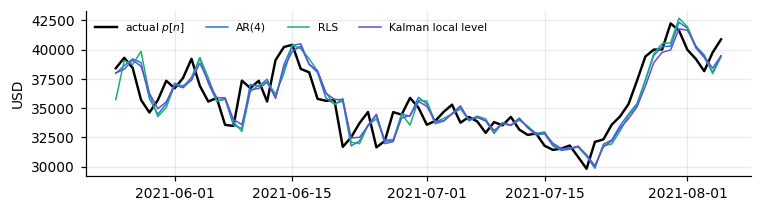

In [10]:
# Predicted vs actual price on the test block
fig, ax = plt.subplots(figsize=(7, 2.0))
d = df.index[S.test]
ax.plot(d, S.p[S.test], color="k", lw=1.6, label="actual $p[n]$")
for name, c in [(f"AR({best['AR']['p']})", COL["AR"]), ("RLS", COL["RLS"]), ("Kalman local level", COL["Kalman local level"])]:
    ax.plot(d, price_pred[name], color=c, lw=1, label=name)
ax.set_ylabel("USD"); ax.legend(fontsize=7, ncol=4, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "fig_test.pdf"); plt.show()

## 4.2 Why validation and test disagree
The adaptive filters were about 11 % better than naive on validation and 12–23 % worse on test. Two explanations are possible:
- **Selection effect:** picking the best of many settings on a short block.
- **Real but temporary structure** in the validation period.

Both are checked below.

In [11]:
blocks = {"fit": np.arange(1, S.val[0]), "validation": S.val, "test": S.test}
rows = []
for name, b in blocks.items():
    x = S.r[b]; ac = acf(x, nlags=4)[1:]
    rows.append({"block": name, "N": len(x), "rho1": ac[0], "rho2": ac[1], "rho3": ac[2], "rho4": ac[3],
                 "bound": 1.96/np.sqrt(len(x)), "LB10 p": acorr_ljungbox(x, lags=[10])["lb_pvalue"].iloc[0], "std": x.std()})
print(pd.DataFrame(rows).set_index("block").round(3))
# Selection effect alone: best RLS setting on validation when the returns are shuffled (no structure at all)
rng = np.random.default_rng(0); best_shuffled = []
for _ in range(40):
    rr = S.r.copy(); rr[1:] = rng.permutation(S.r[1:]); base = np.mean(rr[S.val]**2)
    best_shuffled.append(min(np.mean((rr[S.val] - rls_predict(rr, p, lam, P0_scale=1/S.sigma2_fit)[0][S.val])**2) / base
                             for p in ORDERS for lam in RLS_LAMBDAS))
print(f"best of {len(ORDERS)*len(RLS_LAMBDAS)} RLS settings on shuffled data: mean {np.mean(best_shuffled):.3f}, "
      f"min {np.min(best_shuffled):.3f}  (real data: {summary.loc['RLS','val_mse_rel']:.3f})")
# Were the validation gains significant?
mv = S.mask[S.val]; e_nv_v = (S.p[S.val] - S.p[S.val-1])[mv]
for name in [f"AR({best['AR']['p']})", "LMS", "NLMS", "RLS", "Kalman TV-AR"]:
    e = (S.p[S.val] - S.p[S.val-1]*np.exp(res["rhat"][name][S.val]))[mv]
    print(f"validation DM {name:>14}: stat {dm_test(e, e_nv_v)[0]:+.2f}, p {dm_test(e, e_nv_v)[1]:.3f}")

              N   rho1   rho2   rho3   rho4  bound  LB10 p    std
block                                                            
fit         233  0.008 -0.024  0.050 -0.025  0.128   0.878  0.037
validation   58 -0.311  0.272 -0.087  0.228  0.257   0.035  0.048
test         73 -0.017 -0.141  0.023  0.092  0.229   0.540  0.041


best of 28 RLS settings on shuffled data: mean 0.996, min 0.941  (real data: 0.890)
validation DM          AR(4): stat -0.85, p 0.400
validation DM            LMS: stat -1.54, p 0.129
validation DM           NLMS: stat -1.74, p 0.087
validation DM            RLS: stat -1.08, p 0.285
validation DM   Kalman TV-AR: stat -0.95, p 0.347


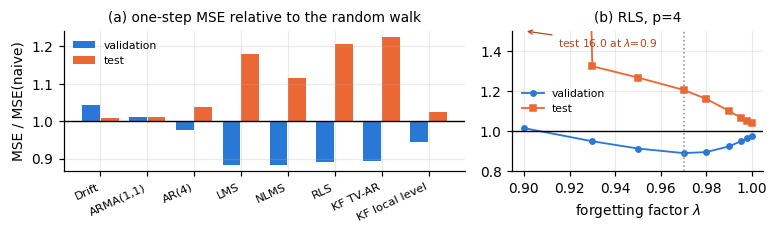

In [12]:
order = ["Drift", "ARMA(1,1)", f"AR({best['AR']['p']})", "LMS", "NLMS", "RLS", "Kalman TV-AR", "Kalman local level"]
val_rel = {}
for name in order:
    key = {"Drift": "Mean (drift)"}.get(name, name)
    rh = rhat_arma if name == "ARMA(1,1)" else res["rhat"][key]
    val_rel[name] = S.mse_r(S.val, rh[S.val]) / S.mse_r(S.val, 0*S.val)
test_rel = table.loc[order, "Rel. MSE vs naive"]
p_rls = best["RLS"]["p"]; lam_grid = np.array([0.9, 0.93, 0.95, 0.97, 0.98, 0.99, 0.995, 0.998, 1.0])
sweep_v, sweep_t = [], []
for lam in lam_grid:
    rh = pred_rls(S, p_rls, lam)
    sweep_v.append(S.mse_r(S.val, rh[S.val]) / S.mse_r(S.val, 0*S.val)); sweep_t.append(S.mse_r(S.test, rh[S.test]) / S.mse_r(S.test, 0*S.test))
fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.2), gridspec_kw={"width_ratios": [1.6, 1]})
xx = np.arange(len(order))
axs[0].bar(xx - 0.2, np.array(list(val_rel.values())) - 1, 0.38, bottom=1, color="#2a78d6", label="validation")
axs[0].bar(xx + 0.2, test_rel.to_numpy() - 1, 0.38, bottom=1, color="#eb6834", label="test")
axs[0].axhline(1, color="k", lw=0.9); axs[0].set_xticks(xx)
axs[0].set_xticklabels([o.replace("Kalman ", "KF ") for o in order], rotation=25, ha="right", fontsize=7.5)
axs[0].set_ylabel("MSE / MSE(naive)"); axs[0].set_title("(a) one-step MSE relative to the random walk", fontsize=9); axs[0].legend(fontsize=7)
axs[1].plot(lam_grid, sweep_v, "o-", color="#2a78d6", ms=3.5, label="validation")
axs[1].plot(lam_grid, sweep_t, "s-", color="#eb6834", ms=3.5, label="test")
axs[1].axhline(1, color="k", lw=0.9); axs[1].axvline(best["RLS"]["lam"], color="#8a8987", ls=":", lw=1)
axs[1].set_ylim(0.8, 1.5)
axs[1].annotate(f"test {sweep_t[0]:.1f} at $\\lambda$=0.9", xy=(0.9, 1.5), xytext=(0.915, 1.42), fontsize=7, color="#b0461d",
                arrowprops=dict(arrowstyle="->", color="#b0461d", lw=0.8))
axs[1].set_xlabel(r"forgetting factor $\lambda$"); axs[1].set_title(f"(b) RLS, p={p_rls}", fontsize=9); axs[1].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "fig_valtest.pdf"); plt.show()

## 4.3 Multi-step forecasts

In [13]:
hz = horizon_errors(S, best, horizons=(1, 5, 10))
print(hz.round(0)); hz.to_csv(TAB / "horizons_2021.csv")

    Naive (random walk)   AR(4)     RLS  Kalman TV-AR  Kalman local level   n
h                                                                            
1                1454.0  1484.0  1606.0        1619.0              1478.0  73
5                3088.0  3160.0  3297.0        3296.0              3080.0  69
10               4080.0  4185.0  4232.0        4207.0              4062.0  64


## 4.4 Open, High and Low (Close hyper-parameters)

In [14]:
def ohlc_rmse(raw_df, end=None):
    base = clean(raw_df.loc[:end] if end else raw_df)
    out = {}
    for col in ["Open", "High", "Low", "Close"]:
        rr = run_all(add_returns(base, col=col), col=col, best=best)
        out[col] = rr["table"]["RMSE [USD]"].rename(index={"Mean (drift)": "Drift"})
    return pd.DataFrame(out).T, base
ohlc, base = ohlc_rmse(load_raw(), "2021-08-05")
print(ohlc.round(0)); ohlc.to_csv(TAB / "ohlc_2021.csv")
o, c = base["Open"].to_numpy(), base["Close"].to_numpy(); mm = S.mask[S.test]
print(f"Open[n] = Close[n-1]: RMSE {np.sqrt(np.mean((o[S.test]-c[S.test-1])[mm]**2)):.0f} USD")

       Naive (random walk)   Drift   AR(4)     LMS    NLMS     RLS  Kalman TV-AR  Kalman local level
Open                1528.0  1533.0  1553.0  1623.0  1601.0  1646.0        1658.0              1528.0
High                1315.0  1324.0  1322.0  1351.0  1365.0  1397.0        1398.0              1341.0
Low                 1382.0  1388.0  1399.0  1549.0  1485.0  1536.0        1535.0              1468.0
Close               1454.0  1462.0  1484.0  1588.0  1539.0  1606.0        1619.0              1478.0
Open[n] = Close[n-1]: RMSE 56 USD


## 4.5 Recent data (1 Oct 2025 – 15 Oct 2026)
Downloaded from the Yahoo Finance chart API on 16 Oct 2026: 380 days with no gaps (SHA-256 in the README). Two tests are run:
- **(a) Re-tuned:** the same tuning procedure applied to the new data.
- **(b) Frozen:** the 2020–21 hyper-parameters applied without any re-tuning. This is the stricter out-of-sample test.

In [15]:
rec_raw = load_raw(RECENT_CSV)
rec = add_returns(clean(rec_raw)); Sr = Series(rec)
print(f"recent: {len(rec)} days; test {rec.index[Sr.test[0]].date()} to {rec.index[Sr.test[-1]].date()} ({len(Sr.test)} days)")
rr_ = rec["r"].dropna().to_numpy()
print(f"std r {rr_.std():.4f}; LB p r: {acorr_ljungbox(rr_, lags=[10,20])['lb_pvalue'].round(3).tolist()}, "
      f"r^2: {acorr_ljungbox(rr_**2, lags=[10,20])['lb_pvalue'].round(5).tolist()}")
rec_res = run_all(rec); rec_frozen = run_all(rec, best=best)
print(rec_res["best"])
cols = ["RMSE [USD]", "Rel. MSE vs naive", "DM p", "LB p (resid.)"]
print("(a) re-tuned\n", rec_res["table"][cols].round(3)); print("(b) frozen 2020-21 settings\n", rec_frozen["table"][cols].round(3))
hl = {}
for col in ["High", "Low"]:
    t_ = run_all(add_returns(clean(rec_raw), col=col), col=col, best=rec_res["best"])["table"]
    hl[col + " RMSE"], hl[col + " rel. MSE"], hl[col + " DM p"] = t_["RMSE [USD]"], t_["Rel. MSE vs naive"], t_["DM p"]
print("recent High/Low (re-tuned settings)\n", pd.DataFrame(hl).round(3))
rec_res["table"].to_csv(TAB / "test_close_recent.csv"); rec_frozen["table"].to_csv(TAB / "test_close_recent_frozen.csv")
pd.DataFrame(hl).to_csv(TAB / "highlow_recent.csv")

recent: 380 days; test 2026-08-01 to 2026-10-15 (76 days)
std r 0.0233; LB p r: [0.295, 0.384], r^2: [0.0, 1e-05]


{'AR': {'p': 0}, 'LMS': {'p': 1, 'c': 0.1}, 'NLMS': {'p': 1, 'mu': 0.1}, 'RLS': {'p': 1, 'lam': 0.95}, 'Kalman TV-AR': {'p': 1, 'q': 0.01}, 'Kalman local level': {'ratio': 10000.0}}
(a) re-tuned
                      RMSE [USD]  Rel. MSE vs naive   DM p  LB p (resid.)
Naive (random walk)    1594.225              1.000    NaN          0.632
Mean (drift)           1616.010              1.033  0.058          0.642
AR(0)                  1594.225              1.000    NaN          0.632
LMS                    1807.857              1.236  0.501          0.318
NLMS                   1595.702              0.998  0.953          0.772
RLS                    1673.201              1.084  0.523          0.920
Kalman TV-AR           1670.191              1.081  0.564          0.937
Kalman local level     1594.233              1.000  0.751          0.632
(b) frozen 2020-21 settings
                      RMSE [USD]  Rel. MSE vs naive   DM p  LB p (resid.)
Naive (random walk)    1594.225              

## 4.6 Full-history robustness (17 Sep 2014 – 15 Oct 2026)
To check whether "close to white" is specific to the course window, every calendar year is tested separately:
- lag-1 correlation;
- Ljung–Box at lag 10 on $r$ and on $r^2$;
- the Lo–MacKinlay variance ratio with its heteroskedasticity-robust $z^*$.

**The variance ratio** $VR(q)=\mathrm{Var}(\sum_{i<q} r[n-i])/(q\,\mathrm{Var}(r[n]))=1+2\sum_{k=1}^{q-1}(1-k/q)\rho(k)$ asks whether the price *chart* trends ($VR>1$) or mean-reverts ($VR<1$) over $q$ days. It is the price-pattern view of the same second-order statistics.

**Data:** Yahoo Finance daily close, rounded to cents (`data/full`).

In [16]:
rfull = load_full()
yt = year_table(rfull)
print(yt.round(3).to_string()); yt.to_csv(TAB / "full_history_by_year.csv")
print("years with LB10 p < 0.05 on r:", list(yt.index[(yt['LB10 p (r)'] < 0.05) & (yt.index != 'all')]),
      "| on r^2:", int(((yt['LB10 p (r^2)'] < 0.05) & (yt.index != 'all')).sum()), "of", len(yt)-1,
      "| max |z*|:", round(yt[['z*(5)', 'z*(20)']].abs().max().max(), 2))

         N    std   rho1  LB10 p (r)  LB10 p (r^2)  VR(5)  z*(5)  VR(20)  z*(20)
year                                                                            
2015   365  0.037  0.004       0.000         0.000  0.884 -0.500   0.707  -0.763
2016   366  0.025 -0.021       0.005         0.000  0.956 -0.251   0.873  -0.338
2017   365  0.049  0.031       0.730         0.000  0.973 -0.173   0.959  -0.133
2018   365  0.043 -0.036       0.312         0.000  1.034  0.255   0.977  -0.075
2019   365  0.035 -0.034       0.286         0.000  0.969 -0.192   1.061   0.188
2020   366  0.040 -0.126       0.005         0.683  0.907 -0.517   0.951  -0.129
2021   365  0.042 -0.054       0.384         0.121  0.936 -0.563   0.967  -0.121
2022   365  0.034 -0.012       0.318         0.226  1.015  0.105   0.849  -0.522
2023   365  0.023  0.014       0.717         0.140  1.170  1.280   1.127   0.450
2024   366  0.028 -0.055       0.569         0.116  0.957 -0.339   1.002   0.007
2025   365  0.022 -0.085    

## Summary (Tables 2–3 of the report)

In [17]:
lab = lambda t: t.rename(index=lambda k: "AR(p*)" if k.startswith("AR(") else k).rename(index={"Mean (drift)": "Drift"})
summ = pd.concat({"2021 test": lab(table)[["RMSE [USD]", "Rel. MSE vs naive", "DM p", "Holm p"]],
                  "2026 re-tuned": lab(rec_res["table"])[["RMSE [USD]", "Rel. MSE vs naive", "DM p"]],
                  "2026 frozen": lab(rec_frozen["table"])[["Rel. MSE vs naive", "DM p"]]}, axis=1)
print(summ.round(3)); print(f"p* = {best['AR']['p']} (2021), {rec_res['best']['AR']['p']} (2026)")

                     2021 test                                 2026 re-tuned                                2026 frozen       
                    RMSE [USD] Rel. MSE vs naive   DM p Holm p    RMSE [USD] Rel. MSE vs naive   DM p Rel. MSE vs naive   DM p
Naive (random walk)   1453.679             1.000    NaN    NaN      1594.225             1.000    NaN             1.000    NaN
Drift                 1461.774             1.008  0.589  1.000      1616.010             1.033  0.058             1.033  0.058
AR(p*)                1484.019             1.039  0.200  0.798      1594.225             1.000    NaN             1.036  0.033
ARMA(1,1)             1460.073             1.012  0.606  1.000           NaN               NaN    NaN               NaN    NaN
LMS                   1587.886             1.179  0.023  0.140      1807.857             1.236  0.501             1.068  0.048
NLMS                  1539.388             1.117  0.013  0.101      1595.702             0.998  0.953          